# Nashville Housing: EDA

We look at 56,374 home sales (2013 to 2016) and answer: **what is the typical price, what affects it, and what looks odd?**

Tools: pandas and matplotlib.

## Step 1: Load and prepare the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('NashvilleHousingCleaned.xlsx')
df.columns = df.columns.str.strip()          # remove stray space in a column name

# Small fixes to the cleaned file
df['LandUse'] = df['LandUse'].replace('RESIDENTIAL RESIDENTIAL CONDO', 'RESIDENTIAL CONDO')
df['TotalValue'] = df['TotalValue'].replace(0, None)   # 0 meant "missing"

# Date helper columns
df['Year'] = df['SaleDate'].dt.year
df['Month'] = df['SaleDate'].dt.month

df.head()

,UniqueID,ParcelID,LandUse,PropertyStreet,PropertyCity,SaleDate,SalePrice,LegalReference,SoldAsVacant,OwnerName,...,Acreage,LandValue,BuildingValue,TotalValue,YearBuilt,Bedrooms,FullBath,HalfBath,Year,Month
0,5138,133 08 0 080.00,SINGLE FAMILY,837 REISCHA CT,NASHVILLE,2013-07-30,90000,20130805-0081559,No,"ZWAEID, HUSSAIN H.",...,0.36,21500.0,88700.0,110200,1981.0,3.0,1.0,0.0,2013,7
1,32536,115 16 0 071.00,SINGLE FAMILY,180 HAVERFORD DR,NASHVILLE,2015-06-30,400000,20150707-0065771,No,"ZURICH HOMES, INC.",...,0.88,170000.0,0.0,170000,NaN,NaN,NaN,NaN,2015,6
2,43280,083 14 0 088.00,SINGLE FAMILY,2005 RUSSELL ST,NASHVILLE,2016-01-20,616000,20160128-0008316,No,"ZUNZ, EMMANUEL",...,0.26,121600.0,279800.0,401400,2006.0,2.0,2.0,2.0,2016,1
3,18418,043 06 0 339.00,SINGLE FAMILY,930 SNOW AVE,MADISON,2014-07-15,118500,20140717-0063142,No,"ZUNIGA, LUIS E. & FIGUEROA, PATRICIA",...,0.25,20000.0,88600.0,108600,1946.0,3.0,2.0,0.0,2014,7
4,44055,127 00 0 257.00,SINGLE FAMILY,8151 CHARLOTTE PIKE,NASHVILLE,2016-02-08,320000,20160210-0012776,No,"ZUNIGA, GUSTAVO",...,1.15,50000.0,146100.0,196100,1965.0,5.0,2.0,0.0,2016,2


In [2]:
# Drop the 2 rows dated 2019 (they look like errors) for the time charts
timed = df[df['Year'] < 2019]
print('Rows:', len(df))

Rows: 56374


## Step 2: Key statistics

In [3]:
df['SalePrice'].describe().round(0)

count       56374.0
mean       327518.0
std        930650.0
min            50.0
25%        135000.0
50%        205696.0
75%        329000.0
max      54278060.0
Name: SalePrice, dtype: float64

**Notice:** the average (mean) is about 327K but the median is about 206K. A few very expensive sales push the average up, so we use the **median** from now on.

## Step 3: Five insights

### Insight 1: Prices rose about 28% from 2013 to 2016

Year
2013    180000.0
2014    195000.0
2015    214500.0
2016    229535.0
Name: SalePrice, dtype: float64


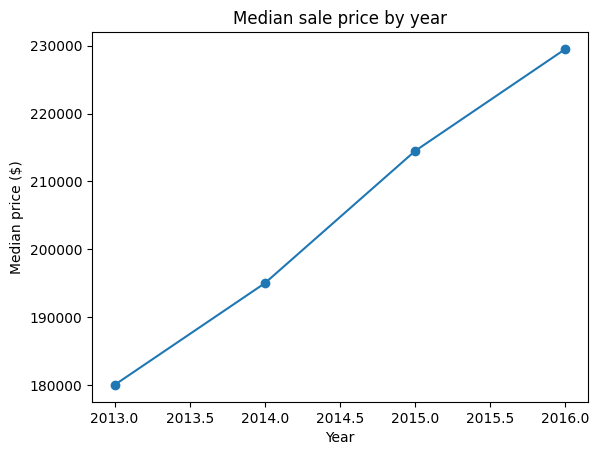

In [4]:
yearly = timed.groupby('Year')['SalePrice'].median()
print(yearly)

yearly.plot(kind='line', marker='o', title='Median sale price by year')
plt.ylabel('Median price ($)')
plt.show()

**Conclusion:** the median price went from 180,000 to 229,535. (2016 only runs to October.)

### Insight 2: Most sales happen in June

Month
1     2211
2     1745
3     2948
4     3555
5     4138
6     4705
7     4408
8     4316
9     3881
10    3509
11    3114
12    3771
dtype: int64


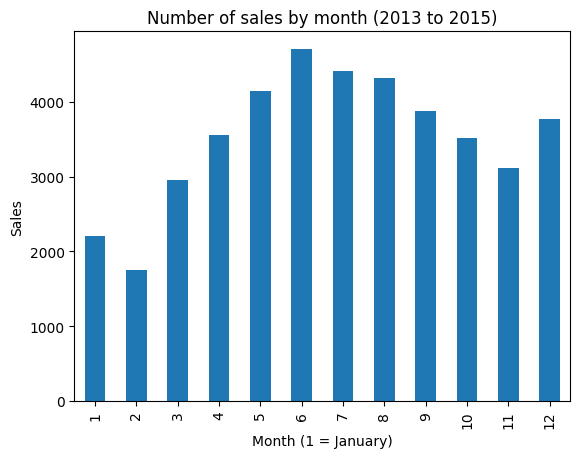

In [5]:
months = timed[timed['Year'] <= 2015].groupby('Month').size()   # 2016 is incomplete, so leave it out
print(months)

months.plot(kind='bar', title='Number of sales by month (2013 to 2015)')
plt.xlabel('Month (1 = January)')
plt.ylabel('Sales')
plt.show()

**Conclusion:** June has about 2.7 times more sales than February. Spring and summer are the busy season.

### Insight 3: Location affects price

                count    median
PropertyCity                   
MADISON          2114  125000.0
OLD HICKORY      1415  149900.0
ANTIOCH          6286  157900.0
GOODLETTSVILLE    735  167000.0
HERMITAGE        3126  173000.0
NASHVILLE       40216  230000.0
BRENTWOOD        1696  278572.5
NOLENSVILLE       494  291484.5


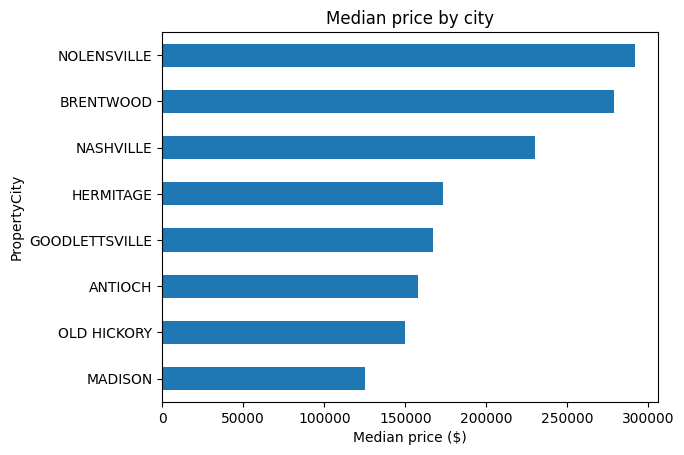

In [6]:
cities = df.groupby('PropertyCity')['SalePrice'].agg(['count', 'median'])
cities = cities[cities['count'] >= 400]                  # only cities with enough sales
cities = cities.sort_values('median')
print(cities)

cities['median'].plot(kind='barh', title='Median price by city')
plt.xlabel('Median price ($)')
plt.show()

**Conclusion:** Nolensville, Brentwood and Mount Juliet cost more than Nashville. Madison is the cheapest of the big areas.

### Insight 4: More bedrooms means a higher price

Bedrooms
1.0    128000.0
2.0    150000.0
3.0    179900.0
4.0    345000.0
5.0    582500.0
6.0    760000.0
Name: SalePrice, dtype: float64


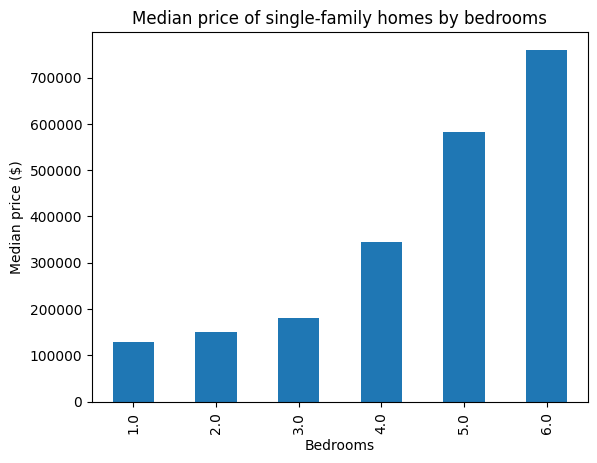

In [7]:
houses = df[(df['LandUse'] == 'SINGLE FAMILY') & (df['Bedrooms'].between(1, 6))]
beds = houses.groupby('Bedrooms')['SalePrice'].median()
print(beds)

beds.plot(kind='bar', title='Median price of single-family homes by bedrooms')
plt.ylabel('Median price ($)')
plt.show()

**Conclusion:** a 3-bedroom home has a median price of about 180K, a 4-bedroom about 345K, and a 5-bedroom about 583K.

### Insight 5: Property type matters

                         count    median
LandUse                                 
SINGLE FAMILY            34120  209000.0
RESIDENTIAL CONDO        14311  222000.0
VACANT RESIDENTIAL LAND   5089  157180.0
DUPLEX                    1372  160000.0
ZERO LOT LINE             1047  105000.0
RESIDENTIAL COMBO/MISC      95  145000.0


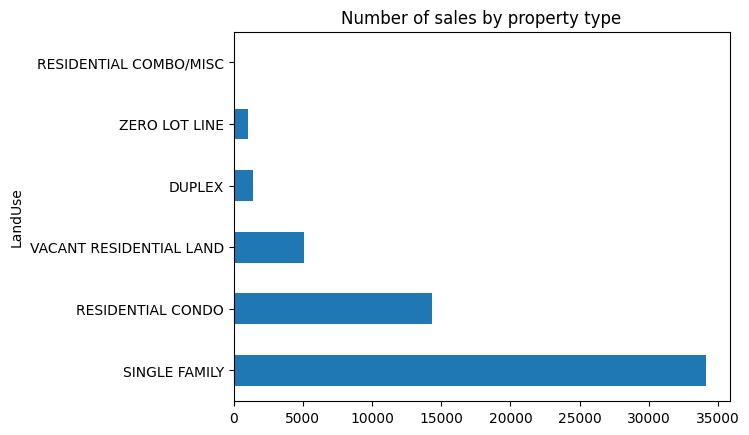

In [8]:
types = df.groupby('LandUse')['SalePrice'].agg(['count', 'median'])
types = types.sort_values('count', ascending=False).head(6)
print(types)

types['count'].plot(kind='barh', title='Number of sales by property type')
plt.show()

**Conclusion:** single-family homes are about 61% of all sales. Condos sell for about the same as houses, and vacant land and duplexes cost less.

## Step 4: Things that look odd (anomalies)

### The same price repeated many times

In [9]:
# Look only at expensive sales ($1M or more), since round prices like $150,000 repeat naturally
big = df[df['SalePrice'] >= 1_000_000]
repeated = big['SalePrice'].value_counts().head(5)
print(repeated)

SalePrice
13156000    92
1600000     77
4250000     54
4700000     47
1242000     46
Name: count, dtype: int64


The price $13,156,000 appears on 92 rows. This is one big deal split across many condo units, not 92 separate sales. It is why the mean is so high.

### Very low prices

In [10]:
low = df[df['SalePrice'] <= 1000]
print(len(low), 'sales are $1,000 or less')
low[['LandUse', 'SalePrice', 'SaleDate']].head()

15 sales are $1,000 or less


,LandUse,SalePrice,SaleDate
416,VACANT RESIDENTIAL LAND,50,2013-03-15
6342,SINGLE FAMILY,1000,2014-06-27
7067,VACANT RESIDENTIAL LAND,750,2016-03-22
16319,VACANT RESIDENTIAL LAND,1000,2014-07-09
16320,VACANT RESIDENTIAL LAND,1000,2014-07-09


These are probably transfers between family members, not real market sales.

### Missing data

In [11]:
missing = df[['Acreage', 'LandValue', 'YearBuilt', 'Bedrooms']].isna().mean() * 100
print(missing.round(0))

Acreage      54.0
LandValue    54.0
YearBuilt    57.0
Bedrooms     57.0
dtype: float64


About half of the rows are missing acreage and land value, including every condo. Keep this in mind when using those columns.

## Summary

1. Prices rose about 28% from 2013 to 2016.
2. June is the busiest month.
3. Suburbs such as Nolensville and Brentwood cost more than Nashville.
4. More bedrooms means a higher price.
5. Single-family homes are most of the sales, and condos cost about the same.

**Important Note:** repeated bulk-sale prices, very low prices, and missing data. Use the median, not the mean.